# AAVAIL Revenue – Exploratory Data Analysis & Model Comparison

**Business question.** AAVAIL management wants to forecast the revenue of the **next 30 days**
for any given day, for each of the top-10 countries and for all countries combined, so that
staffing and budget decisions can be made earlier and with more confidence.

**Null hypothesis tested in the modelling part.** *A machine-learning model does not forecast
30-day revenue better than a naive "same as the last month" baseline.*

**Data.** Invoice-level transactions (`data/cs-train`, Nov 2017 – Jul 2019), delivered as monthly
JSON files with inconsistent column names. Ingestion is automated in `cslib.fetch_data()`.

In [1]:
import os, sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cslib

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e6', 'axes.axisbelow': True})
BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#9e9e9e', '#222222'
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Data ingestion and quality checks

In [2]:
df = cslib.fetch_data(cslib.DATA_DIR)
print('rows x cols:', df.shape)
print('date range :', df.invoice_date.min().date(), '->', df.invoice_date.max().date())
print('countries  :', df.country.nunique(), '| customers:', df.customer_id.nunique(),
      '| invoices:', df.invoice.nunique(), '| streams:', df.stream_id.nunique())
df.head()

rows x cols: (815011, 10)
date range : 2017-11-28 -> 2019-07-31
countries  : 43 | customers: 5225 | invoices: 42646 | streams: 5007


,country,customer_id,day,invoice,month,price,stream_id,times_viewed,year,invoice_date
0,United Kingdom,13085.0,28,489434,11,6.95,85048,12,2017,2017-11-28
1,United Kingdom,13085.0,28,489434,11,6.75,79323W,12,2017,2017-11-28
2,United Kingdom,13085.0,28,489434,11,2.10,22041,21,2017,2017-11-28
3,United Kingdom,13085.0,28,489434,11,1.25,21232,5,2017,2017-11-28
4,United Kingdom,13085.0,28,489434,11,1.65,22064,17,2017,2017-11-28


In [3]:
quality = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2),
})
print('negative prices:', (df.price < 0).sum(), '| zero prices:', (df.price == 0).sum())
print('duplicate rows :', df.duplicated().sum())
quality

negative prices: 3 | zero prices: 5365
duplicate rows : 28844


,missing,missing_%
country,0,0.00
customer_id,189762,23.28
day,0,0.00
invoice,0,0.00
month,0,0.00
price,0,0.00
stream_id,0,0.00
times_viewed,0,0.00
year,0,0.00
invoice_date,0,0.00


**Observations.** `customer_id` is missing for roughly a quarter of the rows (guest purchases), so
customer-level features are not reliable – the forecast is built on aggregated daily revenue,
for which `customer_id` is not needed. A small number of negative/zero prices exist
(refunds / free items); they are kept because they are part of the realised revenue.
Fully identical rows (~3.5 %) are kept as well: the data has no line-item id, so a customer
buying the same stream twice in one invoice produces identical rows that are real revenue.

## 2. Where does the revenue come from?

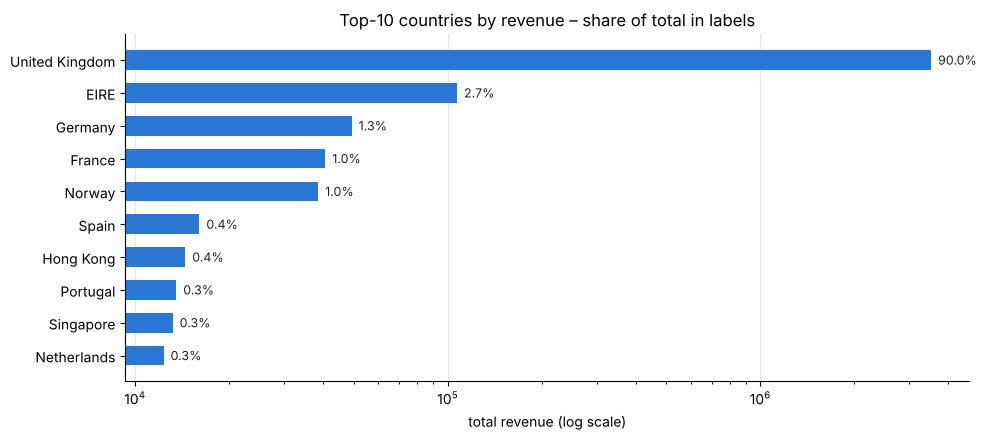

In [4]:
by_country = df.groupby('country')['price'].sum().sort_values(ascending=False)
top10 = by_country.head(10)
share = top10 / by_country.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top10.index[::-1], top10.values[::-1], color=BLUE, height=0.6)
for y, (v, s) in enumerate(zip(top10.values[::-1], share.values[::-1])):
    ax.text(v, y, f'  {s:.1f}%', va='center', color=INK, fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('total revenue (log scale)')
ax.set_title('Top-10 countries by revenue – share of total in labels')
ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_revenue_by_country.png'), dpi=120)

The United Kingdom alone accounts for ~90 % of revenue, so the "all countries" series is almost
the UK series. Small countries have very sparse, spiky revenue – they will be much harder to
forecast and need their own model (one model per country is used).

## 3. Revenue over time

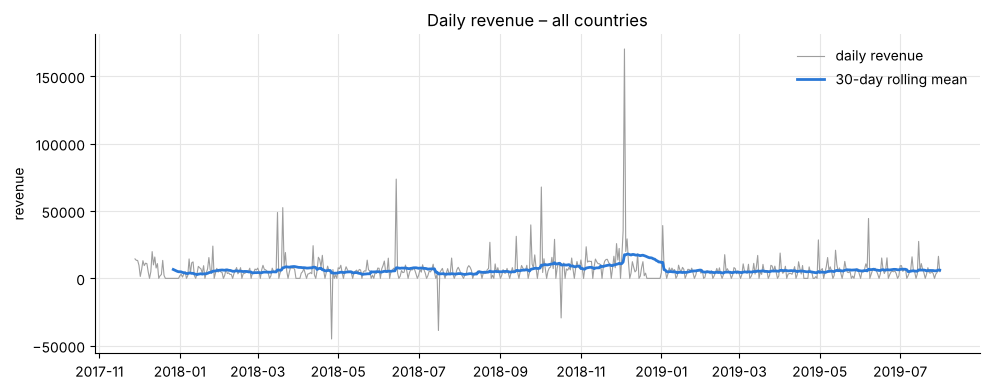

In [5]:
ts = cslib.fetch_ts(cslib.DATA_DIR)
all_ts = ts['all'].set_index('date')

fig, ax = plt.subplots()
ax.plot(all_ts.index, all_ts['revenue'], color=GRAY, lw=0.8, label='daily revenue')
ax.plot(all_ts.index, all_ts['revenue'].rolling(30).mean(), color=BLUE, lw=2, label='30-day rolling mean')
ax.set_ylabel('revenue'); ax.set_title('Daily revenue – all countries')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_daily_revenue.png'), dpi=120)

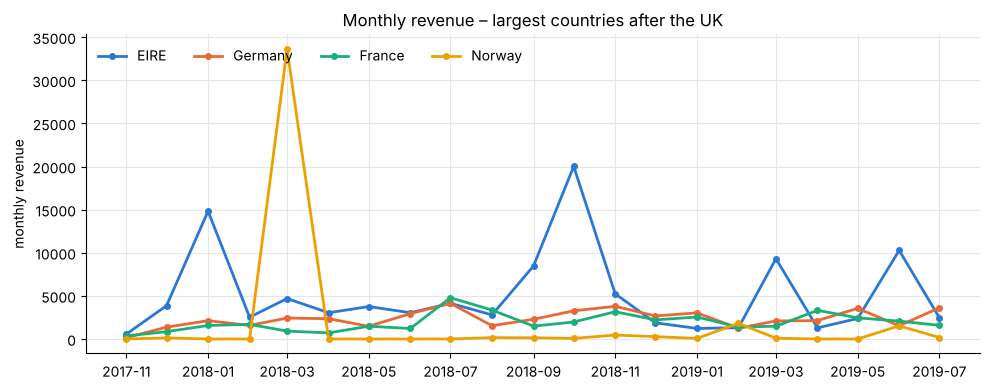

In [6]:
monthly = df.assign(ym=df.invoice_date.dt.to_period('M').dt.to_timestamp()) \
            .groupby(['ym', 'country'])['price'].sum().unstack(fill_value=0)
cols = ['EIRE', 'Germany', 'France', 'Norway']
colors = [BLUE, ORANGE, AQUA, YELLOW]

fig, ax = plt.subplots()
for c, col in zip(cols, colors):
    ax.plot(monthly.index, monthly[c], color=col, lw=2, marker='o', ms=4, label=c)
ax.set_ylabel('monthly revenue'); ax.set_title('Monthly revenue – largest countries after the UK')
ax.legend(frameon=False, ncol=4, loc='upper left')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_monthly_countries.png'), dpi=120)

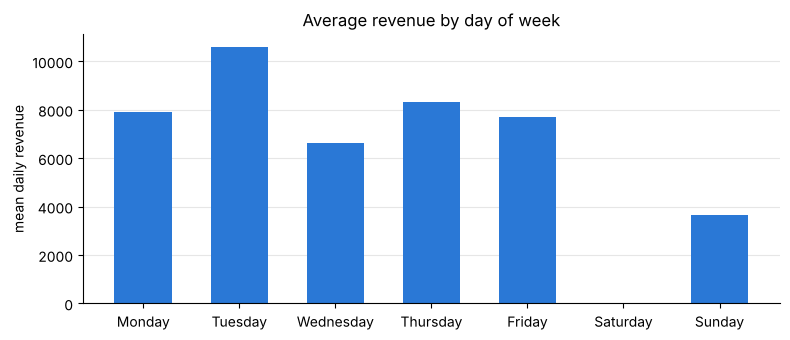

dow
Monday        7906.0
Tuesday      10582.0
Wednesday     6623.0
Thursday      8309.0
Friday        7710.0
Saturday        17.0
Sunday        3647.0
Name: revenue, dtype: float64

In [7]:
dow = all_ts.assign(dow=all_ts.index.day_name()).groupby('dow')['revenue'].mean()
dow = dow.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(dow.index, dow.values, color=BLUE, width=0.6)
ax.set_ylabel('mean daily revenue'); ax.set_title('Average revenue by day of week')
ax.grid(axis='x', visible=False)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_day_of_week.png'), dpi=120)
dow.round(0)

**Observations.**
* Strong **seasonality**: revenue climbs from September and peaks in November (holiday season),
  then drops in December/January. With < 2 years of history, the model sees only one full peak.
* There is an upward **trend** from 2018 to 2019 – tree models trained on raw revenue cannot
  extrapolate above levels seen in training, which motivated learning the *residual on the baseline*.
* Small countries are dominated by one-off spikes (e.g. Norway in March 2018, EIRE in
  Oct 2018) – single large orders, which no daily-revenue model can anticipate.
* Saturdays have (almost) no revenue – the business does not sell on Saturdays, so rolling
  sums over whole weeks are better features than single days.

## 4. Features vs. target

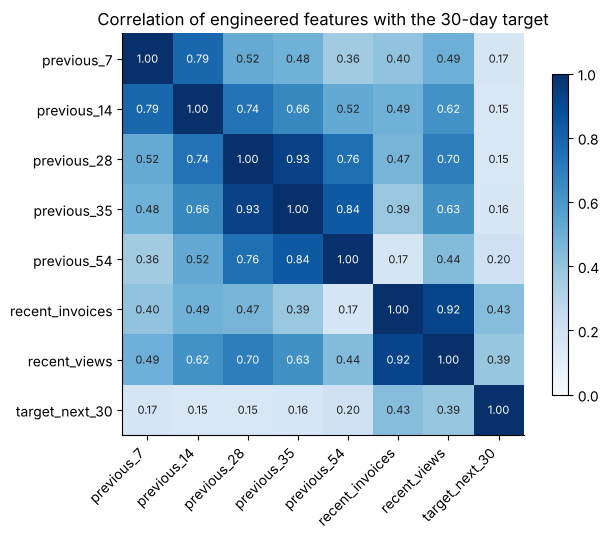

In [8]:
X, y, dates = cslib.engineer_features(ts['all'])
feat = X.assign(target_next_30=y)
corr = feat.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if corr.values[i, j] > 0.6 else INK)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Correlation of engineered features with the 30-day target')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_feature_correlation.png'), dpi=120)

All revenue-window features are positively correlated with the target, longer windows more so.
They are also strongly correlated with each other, so a regularised linear model (Ridge) is a
reasonable candidate next to tree ensembles.

## 5. Model comparison against the baseline

`python model.py` compares, for each country, on a time-ordered hold-out (last 20 % of days,
with a 30-day gap so target windows do not leak):

| model | description |
|---|---|
| **baseline** | next 30 days = last 28 days × 30/28 (naive persistence) |
| ridge | Ridge regression on standardised features, learns the residual over the baseline |
| random_forest | Random forest, residual over the baseline |
| gradient_boosting | Gradient boosting, residual over the baseline |

Hyper-parameters are chosen with `GridSearchCV` + `TimeSeriesSplit(gap=30)`. The best model per
country is refit on all data and saved.

In [9]:
comp = pd.read_csv(os.path.join(ROOT, 'reports', 'model-comparison.csv'))
table = comp.pivot(index='country', columns='model', values='rmse').round(0)
table['selected'] = comp[comp.selected].set_index('country')['model']
table['improvement_vs_baseline_%'] = ((1 - comp[comp.selected].set_index('country')['rmse']
                                       / table['baseline']) * 100).round(1)
table.sort_values('baseline', ascending=False)

model,baseline,gradient_boosting,random_forest,ridge,selected,improvement_vs_baseline_%
country,,,,,,
all,28180.0,40824.0,44019.0,24567.0,ridge,12.8
united_kingdom,25159.0,33565.0,49026.0,21170.0,ridge,15.9
singapore,8561.0,8445.0,8451.0,6366.0,ridge,25.6
eire,6024.0,4741.0,5064.0,4948.0,gradient_boosting,21.3
portugal,4846.0,4741.0,4678.0,3974.0,ridge,18.0
hong_kong,2838.0,1566.0,1346.0,2130.0,random_forest,52.6
france,1580.0,1189.0,1221.0,1236.0,gradient_boosting,24.7
norway,1166.0,3096.0,3168.0,1659.0,baseline,-0.0
germany,878.0,844.0,766.0,575.0,ridge,34.6


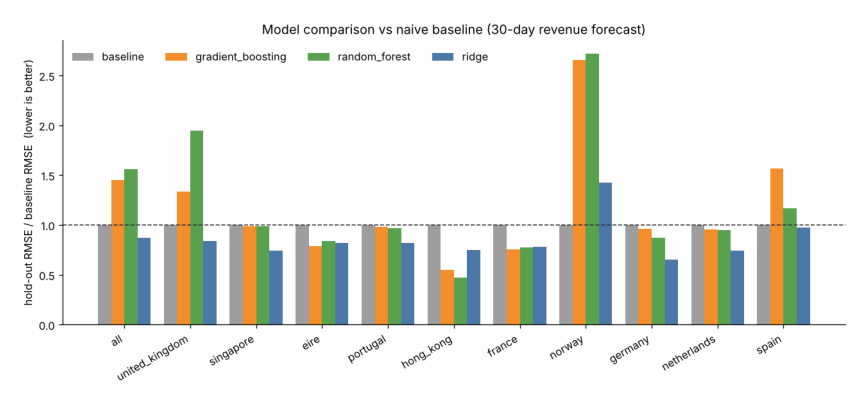

In [10]:
import matplotlib.image as mpimg
img = mpimg.imread(os.path.join(FIG_DIR, 'model_comparison.png'))
fig, ax = plt.subplots(figsize=(11, 5)); ax.imshow(img)
_ = ax.axis('off')

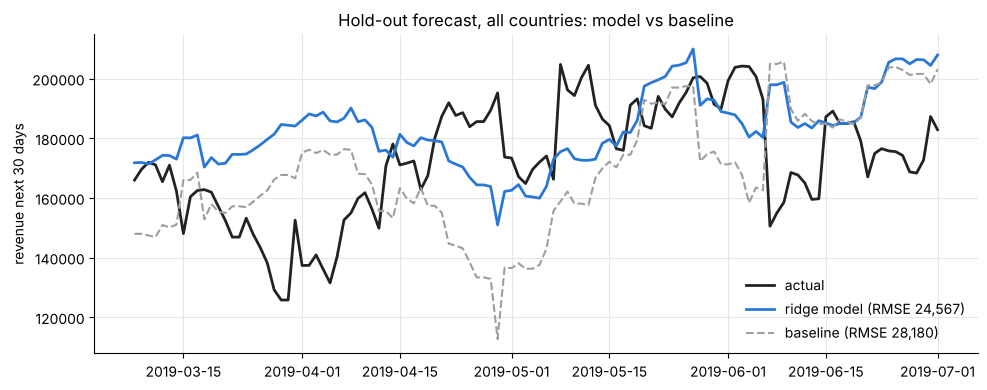

In [11]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from estimators import NaiveBaseline, BaselineResidual
from model import _time_split, rmse

tr, te = _time_split(len(X))
best_alpha = eval(comp[(comp.country == 'all') & (comp.model == 'ridge')]['params'].iloc[0])['reg__alpha']
ridge = BaselineResidual(Pipeline([('scale', StandardScaler()), ('reg', Ridge(alpha=best_alpha))]))
ridge.fit(X.iloc[tr], y[tr])
pred_model, pred_base = ridge.predict(X.iloc[te]), NaiveBaseline().predict(X.iloc[te])
d = pd.to_datetime(dates[te])

fig, ax = plt.subplots()
ax.plot(d, y[te], color=INK, lw=2, label='actual')
ax.plot(d, pred_model, color=BLUE, lw=2, label=f'ridge model (RMSE {rmse(y[te], pred_model):,.0f})')
ax.plot(d, pred_base, color=GRAY, lw=1.5, ls='--', label=f'baseline (RMSE {rmse(y[te], pred_base):,.0f})')
ax.set_ylabel('revenue next 30 days'); ax.set_title('Hold-out forecast, all countries: model vs baseline')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'holdout_all_model_vs_baseline.png'), dpi=120)

## 6. Conclusions

* A model beats the naive baseline for 10 of 11 series (all countries −13 %, UK −16 %, up to −50 %
  for Hong Kong), so the null hypothesis is rejected for those. For Spain the gain is marginal
  (~3 %), and for Norway the baseline itself is selected and deployed – a deliberate, honest choice.
* Ridge on the residual is usually best: the data are small (~580 days) and features are highly
  collinear, which favours a regularised linear model over deep tree ensembles.
* **Production monitoring** (`python monitoring.py`, see the README) shows errors rising on
  Aug–Nov 2019 data: the holiday peak is larger than anything in training. This is exactly the
  situation the monitoring alerts are built for – the recommended action is to retrain with the
  new months (`POST /train {"mode": "prod"}`) and, once two seasons are available, add a
  "same period last year" feature.